<a href="https://colab.research.google.com/github/bilal-basheerai/Gridguard/blob/main/Gridguard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
from google.colab import drive
drive.mount('/content/drive')

ZIP = "/content/drive/MyDrive/gridguard/data/london_smart_meters_dataset_without_missing_values.zip"
!cp "{ZIP}" /content/data.zip
!unzip -o -q /content/data.zip -d /content/raw
!ls -lh /content/raw

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
total 933M
-rw-r--r-- 1 root root 933M Jun 17  2020 london_smart_meters_dataset_without_missing_values.ts


In [22]:
import glob
import numpy as np
import pandas as pd

path = glob.glob("/content/raw/*.ts")[0]      # finds the file whatever its name
print("Using:", path)

START = pd.Timestamp("2013-01-01 00:00")
N_STEPS = 365 * 48                            # 17,520 half-hourly readings
idx = pd.date_range(START, periods=N_STEPS, freq="30min")
N_METERS = 300

with open(path) as f:
    text = f.read()
lines = text.split("@data", 1)[1].strip().splitlines()
del text
print("Households in file:", len(lines))
assert len(lines) == 5560, "File incomplete: expected 5560 households"

rng = np.random.default_rng(42)               # fixed seed = reproducible sample
data = {}
for i in rng.permutation(len(lines)):
    name, ts, vals = lines[i].split(":", 2)
    start = pd.to_datetime(ts, format="%Y-%m-%d %H-%M-%S").floor("30min")
    offset = int((START - start) / pd.Timedelta("30min"))
    if offset < 0:
        continue
    values = vals.split(",")
    if len(values) < offset + N_STEPS:
        continue
    data[name] = np.array(values[offset:offset + N_STEPS], dtype="float32")
    if len(data) == N_METERS:
        break

df = pd.DataFrame(data, index=idx)
df.index.name = "timestamp"
print("Table shape:", df.shape)

df.to_parquet("/content/drive/MyDrive/gridguard/data/meters_2013.parquet")
print("Saved")

Using: /content/raw/london_smart_meters_dataset_without_missing_values.ts
Households in file: 5560
Table shape: (17520, 300)
Saved


In [23]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd
df = pd.read_parquet("/content/drive/MyDrive/gridguard/data/meters_2013.parquet")
df.shape

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


(17520, 300)

Missing values: 0
Negative values: 0


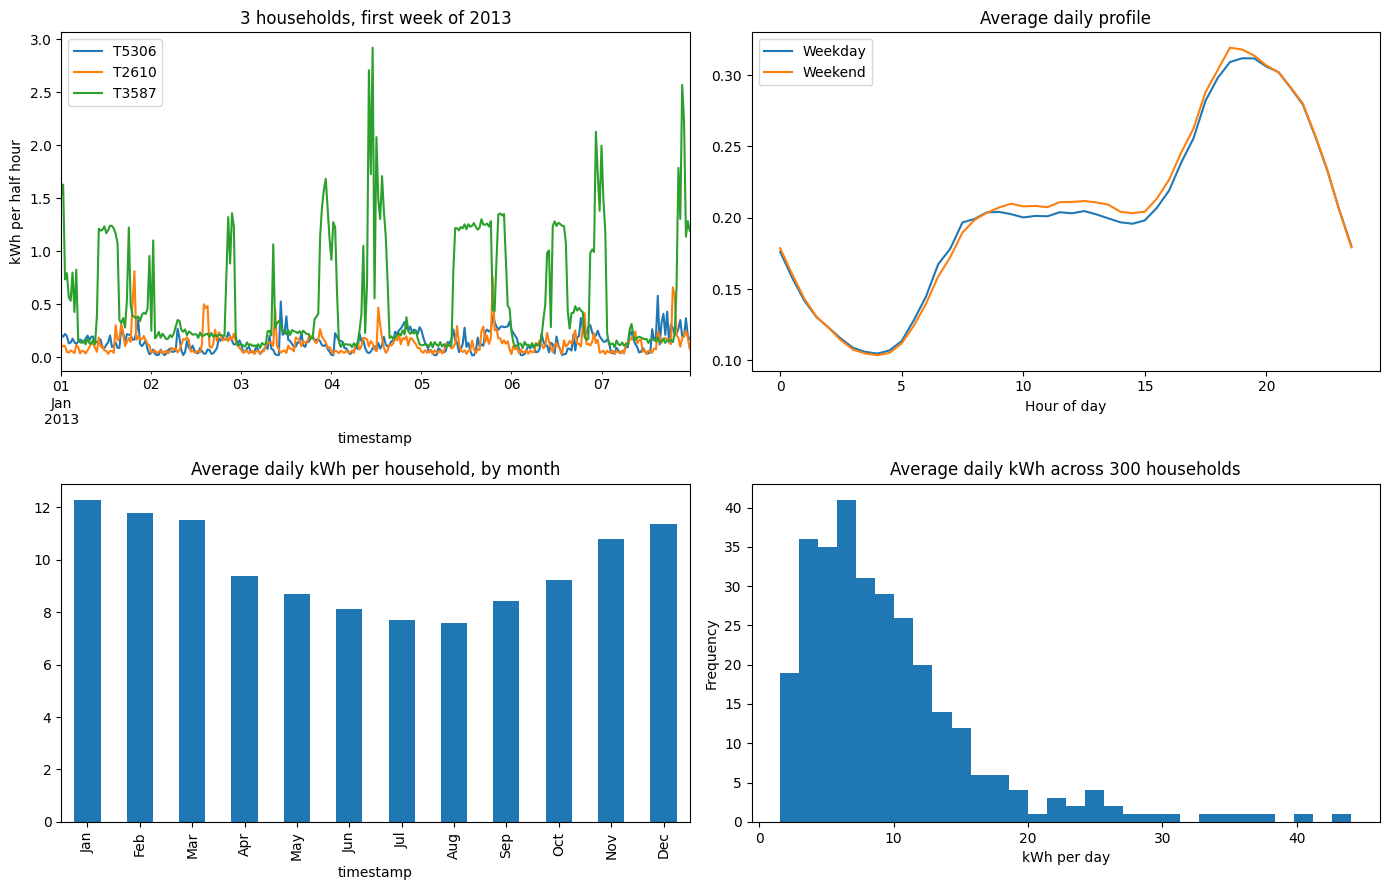

In [24]:
import matplotlib.pyplot as plt

print("Missing values:", int(df.isna().sum().sum()))
print("Negative values:", int((df < 0).sum().sum()))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1) Three households, first week
df.iloc[:48*7, :3].plot(ax=axes[0, 0], title="3 households, first week of 2013")
axes[0, 0].set_ylabel("kWh per half hour")

# 2) Average daily profile, weekday vs weekend
avg = df.mean(axis=1)
hour = avg.index.hour + avg.index.minute / 60
weekend = avg.index.dayofweek >= 5
avg[~weekend].groupby(hour[~weekend]).mean().plot(ax=axes[0, 1], label="Weekday")
avg[weekend].groupby(hour[weekend]).mean().plot(ax=axes[0, 1], label="Weekend")
axes[0, 1].set_title("Average daily profile")
axes[0, 1].set_xlabel("Hour of day")
axes[0, 1].legend()

# 3) Seasonal pattern
monthly = df.resample("MS").mean().mean(axis=1) * 48
monthly.index = monthly.index.strftime("%b")
monthly.plot(kind="bar", ax=axes[1, 0], title="Average daily kWh per household, by month")

# 4) Spread across households
(df.mean() * 48).plot(kind="hist", bins=30, ax=axes[1, 1],
                      title="Average daily kWh across 300 households")
axes[1, 1].set_xlabel("kWh per day")

plt.tight_layout()
plt.show()

# GridGuard 01: Data loading and exploration